# Machine Learning ki Doosri Class: Polynomial Regression 📈

**AI for Everyone** | Instructor: Mian Muhammad Azam Ayaz

Pichli class mein humne **Linear Regression** seekhi thi, jo data mein ek **seedhi line** fit karti hai. Aaj hum uska agla level seekhenge:

1. **Polynomial Regression** kya hai aur kab use karte hain
2. Real data ki **Preprocessing** (ganda data saaf karna)
3. **Underfitting aur Overfitting** kya hota hai
4. **Feature Scaling, Pipeline aur Cross Validation**
5. **Epoch, Batch, Learning Rate aur Loss** kya hote hain
6. Model ko **Pickle file** mein save karna aur wapis load kar ke use karna

Dataset: `Salary_Data.csv` (logon ki age, gender, education, job title, experience aur salary)

> **Kaise chalana hai:** Har cell ko upar se neeche order mein run karo. Cell select karo aur `Shift + Enter` dabao.

---
## Part 1: Polynomial Regression kya hai? 🤔

### Problem: Har relation seedhi line nahi hota
Socho ek fresh graduate ki salary. Pehle 5 saal mein salary **tezi se** barhti hai, phir 15 to 20 saal baad barhna **slow** ho jata hai. Agar isko graph pe banao to ye **seedhi line nahi, balkay curve** banta hai.

Linear Regression sirf seedhi line bana sakti hai, isliay curve wale data pe wo theek fit nahi hoti.

### Solution: Polynomial Regression
**Definition:** Polynomial Regression, Linear Regression ka hi advanced version hai jo input feature ki **powers** (x², x³ waghaira) bhi add kar deta hai. Is se model **curve** bana sakta hai.

| | Formula | Shape |
|---|---|---|
| Linear | $y = m_1x + c$ | Seedhi line ➖ |
| Polynomial (degree 2) | $y = m_1x + m_2x^2 + c$ | Ek mor wala curve ⤴️ |
| Polynomial (degree 3) | $y = m_1x + m_2x^2 + m_3x^3 + c$ | Do mor wala curve 〰️ |

### Degree kya hai?
**Degree** batati hai ke x ki sab se bari power kitni hogi. Degree jitni zyada, curve utna zyada mur sakta hai.

### Ek interesting baat 💡
Polynomial Regression andar se **wohi Linear Regression** hai! Hum bas x se naye columns bana dete hain (x², x³) aur phir normal Linear Regression chala dete hain. Isliay sklearn mein iski koi alag class nahi, balkay hum `PolynomialFeatures` + `LinearRegression` mila kar use karte hain.

---
## Step 1: Libraries import karna 📦

Pichli class wali libraries ke ilawa kuch nayi bhi hain:
- **PolynomialFeatures:** x se x², x³ wale naye columns banata hai
- **StandardScaler:** Sab features ko ek jaisi range mein laata hai
- **Pipeline:** Kai steps ko jor kar ek model bana deta hai
- **cross_val_score:** Model ko behtar tareeqe se test karta hai
- **SGDRegressor:** Aisa model jo epochs mein seekhta hai (Part C mein)
- **pickle:** Model ko file mein save karne ke liay

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pickle

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression, SGDRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

print("Sab libraries load ho gayin ✅")

Sab libraries load ho gayin ✅


---
## Step 2: Dataset load karna 📂

> **Google Colab use kar rahe ho?** Neeche wale cell mein upload wali lines ke aage se `#` hata do, run karo, aur `Salary_Data.csv` select kar lo.

In [2]:
# Sirf Google Colab ke liay (zaroorat ho to # hata do):
# from google.colab import files
# uploaded = files.upload()

df = pd.read_csv("Salary_Data.csv")
df.head()

,Age,Gender,Education Level,Job Title,Years of Experience,Salary
0,32.0,Male,Bachelor's,Software Engineer,5.0,90000.0
1,28.0,Female,Master's,Data Analyst,3.0,65000.0
2,45.0,Male,PhD,Senior Manager,15.0,150000.0
3,36.0,Female,Bachelor's,Sales Associate,7.0,60000.0
4,52.0,Male,Master's,Director,20.0,200000.0


Columns ka matlab:
- `Age`: Umar
- `Gender`: Male, Female ya Other
- `Education Level`: Taleem (High School, Bachelor's, Master's, PhD)
- `Job Title`: Kaam ka naam
- `Years of Experience`: Kitne saal ka tajurba
- `Salary`: Saalana tankhwah (ye hamara **target y** hai)

---
## Step 3: Data ko samajhna 🔍

In [3]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
df.info()

Rows: 6704
Columns: 6
<class 'pandas.DataFrame'>
RangeIndex: 6704 entries, 0 to 6703
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Age                  6702 non-null   float64
 1   Gender               6702 non-null   str    
 2   Education Level      6701 non-null   str    
 3   Job Title            6702 non-null   str    
 4   Years of Experience  6701 non-null   float64
 5   Salary               6699 non-null   float64
dtypes: float64(3), str(3)
memory usage: 314.4 KB


In [4]:
df.describe()

,Age,Years of Experience,Salary
count,6702.000000,6701.000000,6699.000000
mean,33.620859,8.094687,115326.964771
std,7.614633,6.059003,52786.183911
min,21.000000,0.000000,350.000000
25%,28.000000,3.000000,70000.000000
50%,32.000000,7.000000,115000.000000
75%,38.000000,12.000000,160000.000000
max,62.000000,34.000000,250000.000000


---
# 🧹 Step 4: Data Preprocessing (Data ki safai)

Real duniya ka data kabhi saaf nahi hota. Is dataset mein bhi **4 problems** hain. Hum ek ek kar ke pakrein ge aur theek karein ge. Ye ML ka sab se zaroori hissa hai, kyunke:

> **Garbage In = Garbage Out** 🗑️ Ganda data doge to model bhi ghalat seekhe ga.

### 4.1 Problem 1: Missing values (khali cells)

In [5]:
df.isnull().sum()

Age                    2
Gender                 2
Education Level        3
Job Title              2
Years of Experience    3
Salary                 5
dtype: int64

Kuch rows mein values khali hain. Inko handle karne ke 2 tareeqe hote hain:
1. **Fill karna:** Khali jagah pe average (mean) daal do
2. **Drop karna:** Wo row hi hata do

Yahan sirf chand rows khali hain (6700 mein se), aur kuch mein to **Salary hi missing** hai. Salary hamara target hai, uski jagah average daal kar model ko **jhooti salary** sikhana theek nahi. Isliay hum ye rows **drop** kar dete hain.

> 💡 **Rule of thumb:** Agar missing rows bohat kam hain to drop kar do. Agar zyada hain to fill karo, lekin target column ko kabhi fake value se fill na karo.

In [6]:
print("Pehle rows:", len(df))
df = df.dropna()
print("Missing wali rows hatane ke baad:", len(df))

Pehle rows: 6704
Missing wali rows hatane ke baad: 6698


### 4.2 Problem 2: Duplicate rows (aik jaisi rows) ⚠️

Ye is dataset ki **sab se bari chhupi hui problem** hai. Chalo ginte hain kitni rows bilkul copy hain:

In [7]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 4911


**Lagbhag 4900 rows duplicate hain!** Matlab ek hi insaan ka data baar baar likha hua hai.

**Ye nuqsaan kyun karta hai?** Exam wali misaal yaad karo. Agar wohi sawal jo practice mein the, exam mein bhi aa jayein, to student ratta laga kar full marks le lega aur hum samjhenge wo genius hai. Duplicates ke sath bhi yahi hota hai. Ek copy **train** mein chali jati hai aur doosri **test** mein, aur model ka score **jhoota high** aata hai.

Isliay duplicates hatana zaroori hai.

In [8]:
df = df.drop_duplicates().reset_index(drop=True)
print("Duplicates hatane ke baad rows:", len(df))

Duplicates hatane ke baad rows: 1787


### 4.3 Problem 3: Ek hi cheez ke alag alag naam ✏️

In [9]:
df["Education Level"].value_counts()

Education Level
Bachelor's Degree    506
Master's Degree      446
PhD                  340
Bachelor's           262
Master's             122
High School          110
phD                    1
Name: count, dtype: int64

Dekho! `Bachelor's` aur `Bachelor's Degree` dono ek hi cheez hain, lekin computer inhe **alag** samjhe ga. Isi tarah `PhD` aur `phD`. Inko ek jaisa bana dete hain.

In [10]:
df["Education Level"] = df["Education Level"].replace({
    "Bachelor's Degree": "Bachelor's",
    "Master's Degree": "Master's",
    "phD": "PhD"
})

df["Education Level"].value_counts()

Education Level
Bachelor's     768
Master's       568
PhD            341
High School    110
Name: count, dtype: int64

Ab sirf 4 saaf categories hain. ✅

### 4.4 Text ko numbers mein badalna (Encoding) 🔢

Model sirf numbers samajhta hai. Har text column ke liay sahi tareeqa alag hota hai.

**A) Education Level: Ordinal Encoding**

Education mein ek **order** hai: High School < Bachelor's < Master's < PhD. Isliay hum khud order ke hisaab se number dete hain.

> ⚠️ `LabelEncoder` yahan use nahi karna chahiye, kyunke wo **alphabetical order** mein number deta hai (Bachelor's=0, High School=1, Master's=2, PhD=3). Is se model samjhe ga High School, Bachelor's se behtar hai, jo ghalat hai!

In [11]:
education_map = {"High School": 0, "Bachelor's": 1, "Master's": 2, "PhD": 3}
df["Education"] = df["Education Level"].map(education_map)

df[["Education Level", "Education"]].drop_duplicates().sort_values("Education")

,Education Level,Education
721,High School,0
0,Bachelor's,1
1,Master's,2
2,PhD,3


**B) Gender: One-Hot Encoding**

Gender mein koi order nahi (Male, Female se "bara" nahi). Isliay har option ka alag 0/1 column banate hain, jaise pichli class mein `furnishingstatus` ke sath kiya tha. `drop_first=True` ek column hata deta hai kyunke baqi do se wo khud pata chal jata hai.

In [12]:
df = pd.get_dummies(df, columns=["Gender"], drop_first=True, dtype=int)
df.head()

,Age,Education Level,Job Title,Years of Experience,Salary,Education,Gender_Male,Gender_Other
0,32.0,Bachelor's,Software Engineer,5.0,90000.0,1,1,0
1,28.0,Master's,Data Analyst,3.0,65000.0,2,0,0
2,45.0,PhD,Senior Manager,15.0,150000.0,3,1,0
3,36.0,Bachelor's,Sales Associate,7.0,60000.0,1,0,0
4,52.0,Master's,Director,20.0,200000.0,2,1,0


### 4.5 Problem 4: Job Title mein bohat zyada categories 💼

In [13]:
print("Alag alag Job Titles:", df["Job Title"].nunique())
df["Job Title"].value_counts().head(10)

Alag alag Job Titles: 191


Job Title
Software Engineer Manager    127
Full Stack Engineer          122
Senior Software Engineer      96
Senior Project Engineer       95
Back end Developer            81
Data Scientist                80
Software Engineer             78
Front end Developer           71
Marketing Manager             55
Product Manager               53
Name: count, dtype: int64

**190 se zyada** alag job titles hain! Agar inki One-Hot Encoding karein to 190 naye columns ban jayein ge, aur bohat se titles sirf 1 ya 2 baar aate hain, jin se model kuch seekh nahi sakta.

**Smart tareeqa: Feature Engineering** 🧠 Hum title se kaam ki cheez nikal lete hain, yani insaan ka **level**:
- Title mein "Senior", "Lead", "Principal" hai ➜ `Is_Senior = 1`
- "Manager", "Director", "Head", "VP", "Chief" hai ➜ `Is_Manager = 1`
- "Junior", "Assistant", "Intern", "Coordinator" hai ➜ `Is_Junior = 1`

Phir original `Job Title` column hata dete hain.

In [14]:
title = df["Job Title"].str.lower()

df["Is_Senior"]  = title.str.contains("senior|sr|lead|principal").astype(int)
df["Is_Manager"] = title.str.contains("manager|director|head|vp|chief|ceo|cto").astype(int)
df["Is_Junior"]  = title.str.contains("junior|jr|assistant|intern|coordinator").astype(int)

df[["Job Title", "Is_Senior", "Is_Manager", "Is_Junior"]].sample(8, random_state=1)

,Job Title,Is_Senior,Is_Manager,Is_Junior
1159,Junior HR Generalist,0,0,1
654,Back end Developer,0,0,0
764,Software Engineer Manager,0,1,0
1399,Marketing Coordinator,0,0,1
1742,Marketing Manager,0,1,0
983,Back end Developer,0,0,0
194,Senior Marketing Coordinator,1,0,1
921,Data Scientist,0,0,0


In [15]:
# Purane text columns ab zaroori nahi
df = df.drop(columns=["Job Title", "Education Level"])

df.head()

,Age,Years of Experience,Salary,Education,Gender_Male,Gender_Other,Is_Senior,Is_Manager,Is_Junior
0,32.0,5.0,90000.0,1,1,0,0,0,0
1,28.0,3.0,65000.0,2,0,0,0,0,0
2,45.0,15.0,150000.0,3,1,0,1,1,0
3,36.0,7.0,60000.0,1,0,0,0,0,0
4,52.0,20.0,200000.0,2,1,0,0,1,0


**Preprocessing mukammal! 🎉** Ab saara data saaf aur numbers mein hai. Ek nazar correlation pe dalte hain:

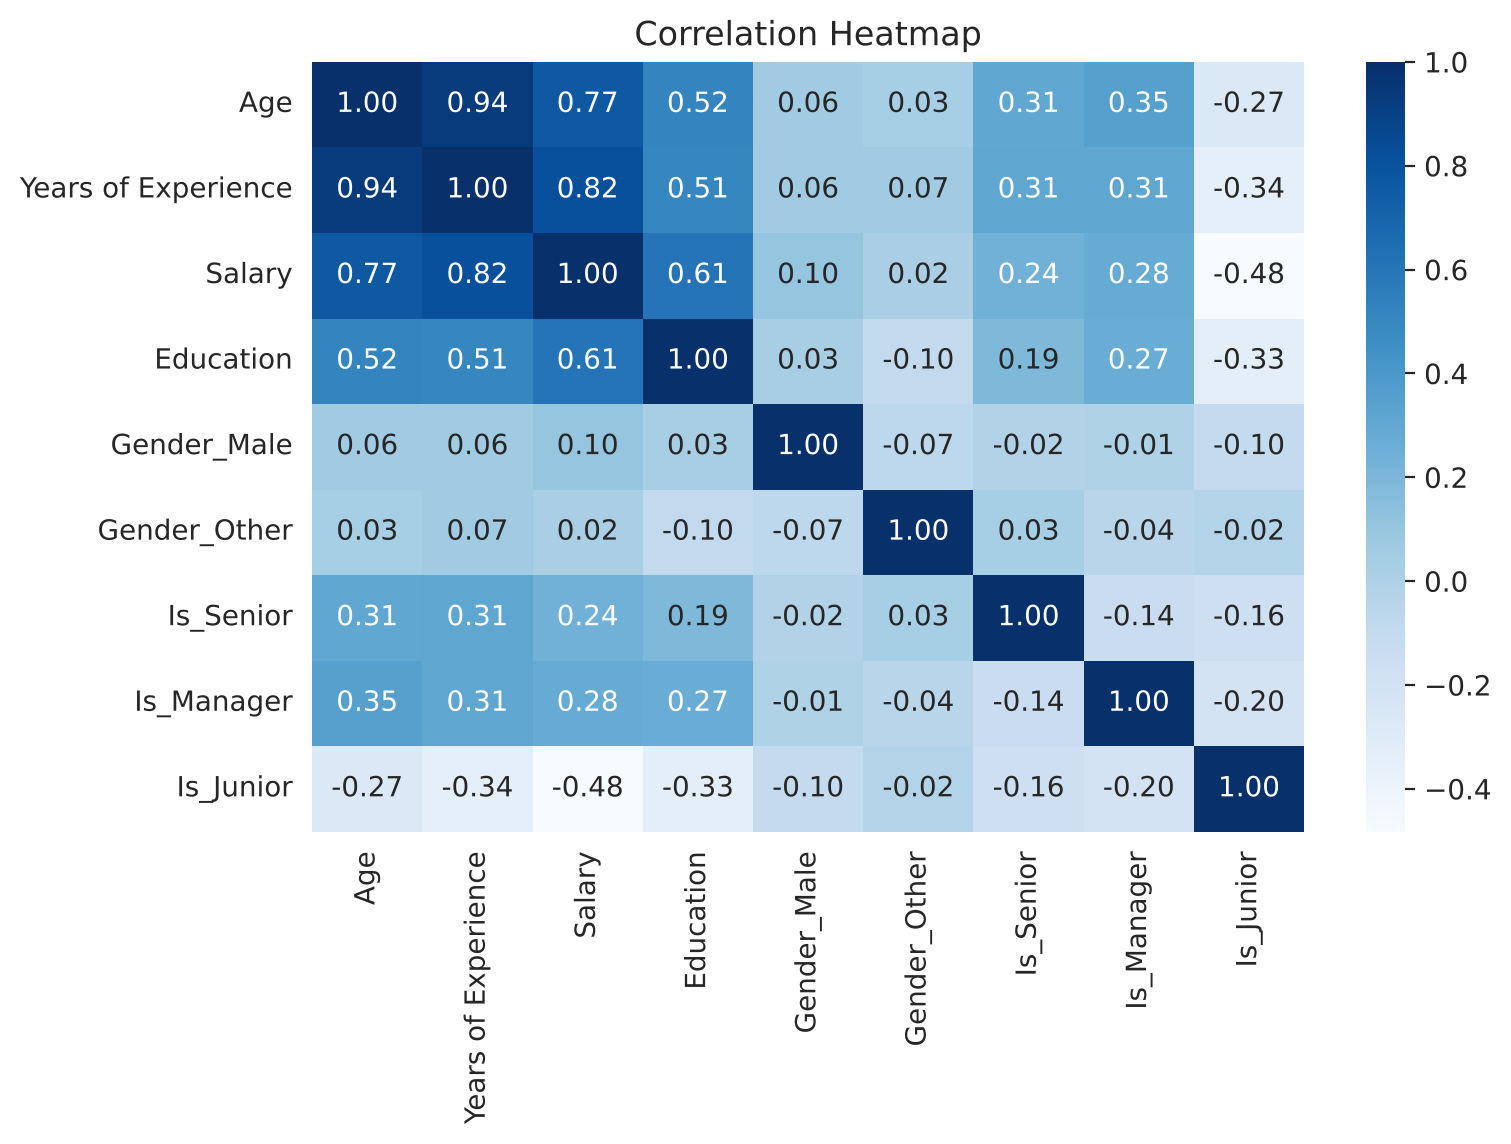

In [16]:
sns.heatmap(df.corr(), annot=True, cmap="Blues", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

**Observation:** `Years of Experience` ka Salary se sab se strong relation hai. `Age` aur `Experience` aapas mein bhi bohat milte hain (0.94), jo samajh mein aata hai. Umar barhti hai to tajurba bhi barhta hai.

---
# 🅰️ Part A: Ek feature ke sath Polynomial Regression

Pehle sirf **Years of Experience** se Salary predict karte hain, taa ke curve apni aankhon se dekh sakein.

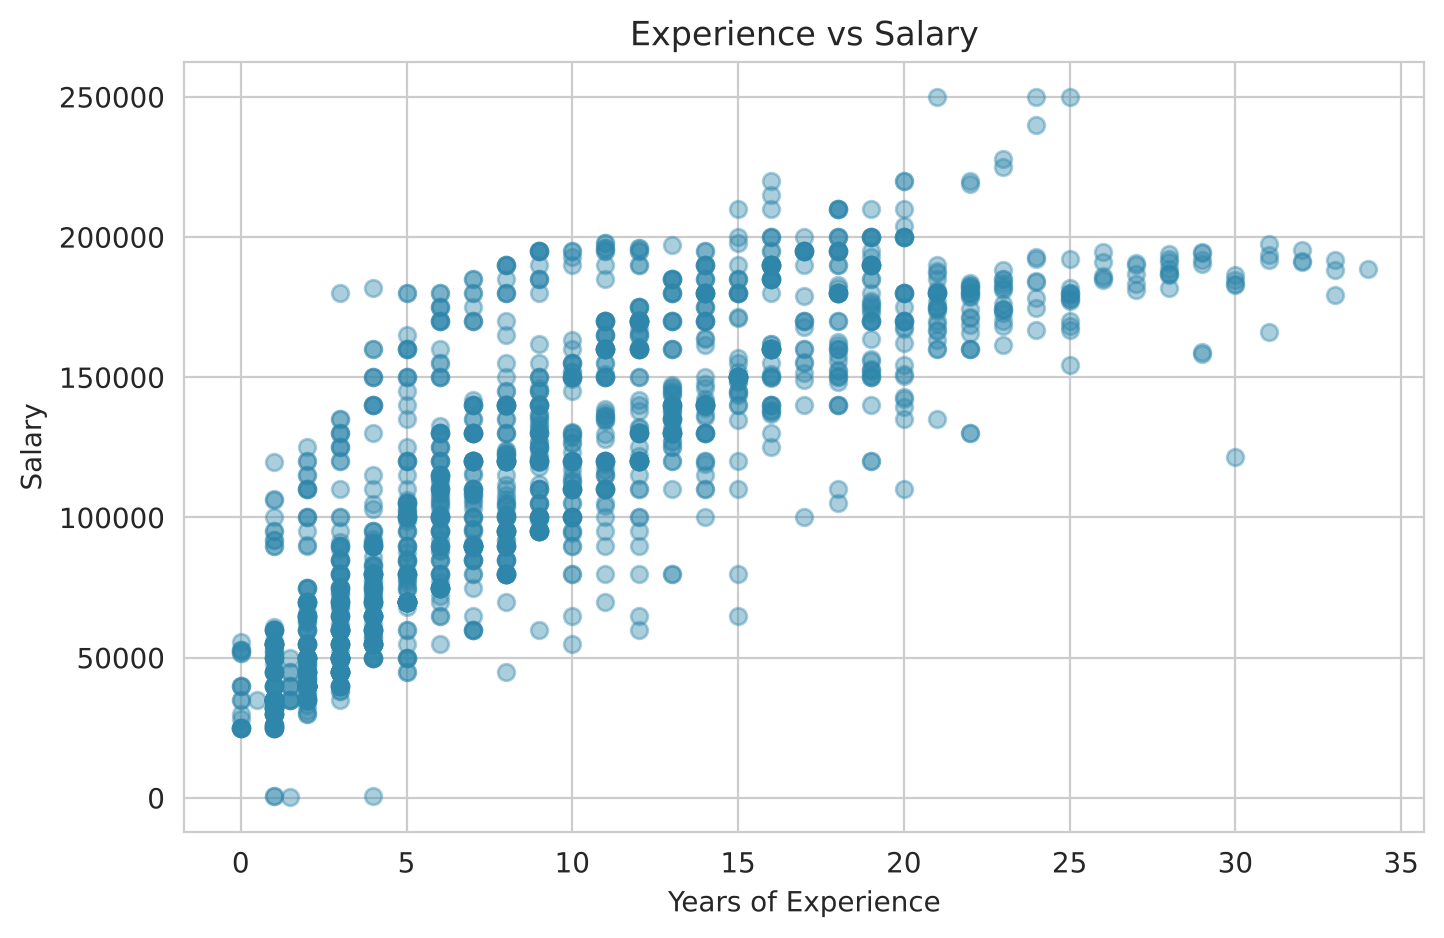

In [17]:
plt.scatter(df["Years of Experience"], df["Salary"], alpha=0.4, color="#2E86AB")
plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.title("Experience vs Salary")
plt.show()

Dekho, shuru mein salary tezi se upar jati hai aur baad mein **flat** hone lagti hai. Ye seedhi line nahi, **curve** hai!

### PolynomialFeatures andar kya karta hai? 🔬
Ek chhoti si misaal se dekhte hain. Agar experience = 2, 3, 5 ho, aur degree = 2:

In [18]:
demo = pd.DataFrame({"x": [2, 3, 5]})

poly_demo = PolynomialFeatures(degree=2, include_bias=False)
result = poly_demo.fit_transform(demo)

pd.DataFrame(result, columns=poly_demo.get_feature_names_out())

,x,x^2
0,2.0,4.0
1,3.0,9.0
2,5.0,25.0


Bas itna hi! Ye **x²** ka naya column bana deta hai (2²=4, 3²=9, 5²=25). Phir Linear Regression in dono columns se seekhti hai. Isi wajah se curve ban jata hai. ✨

### Ab Linear vs Polynomial ka muqabla

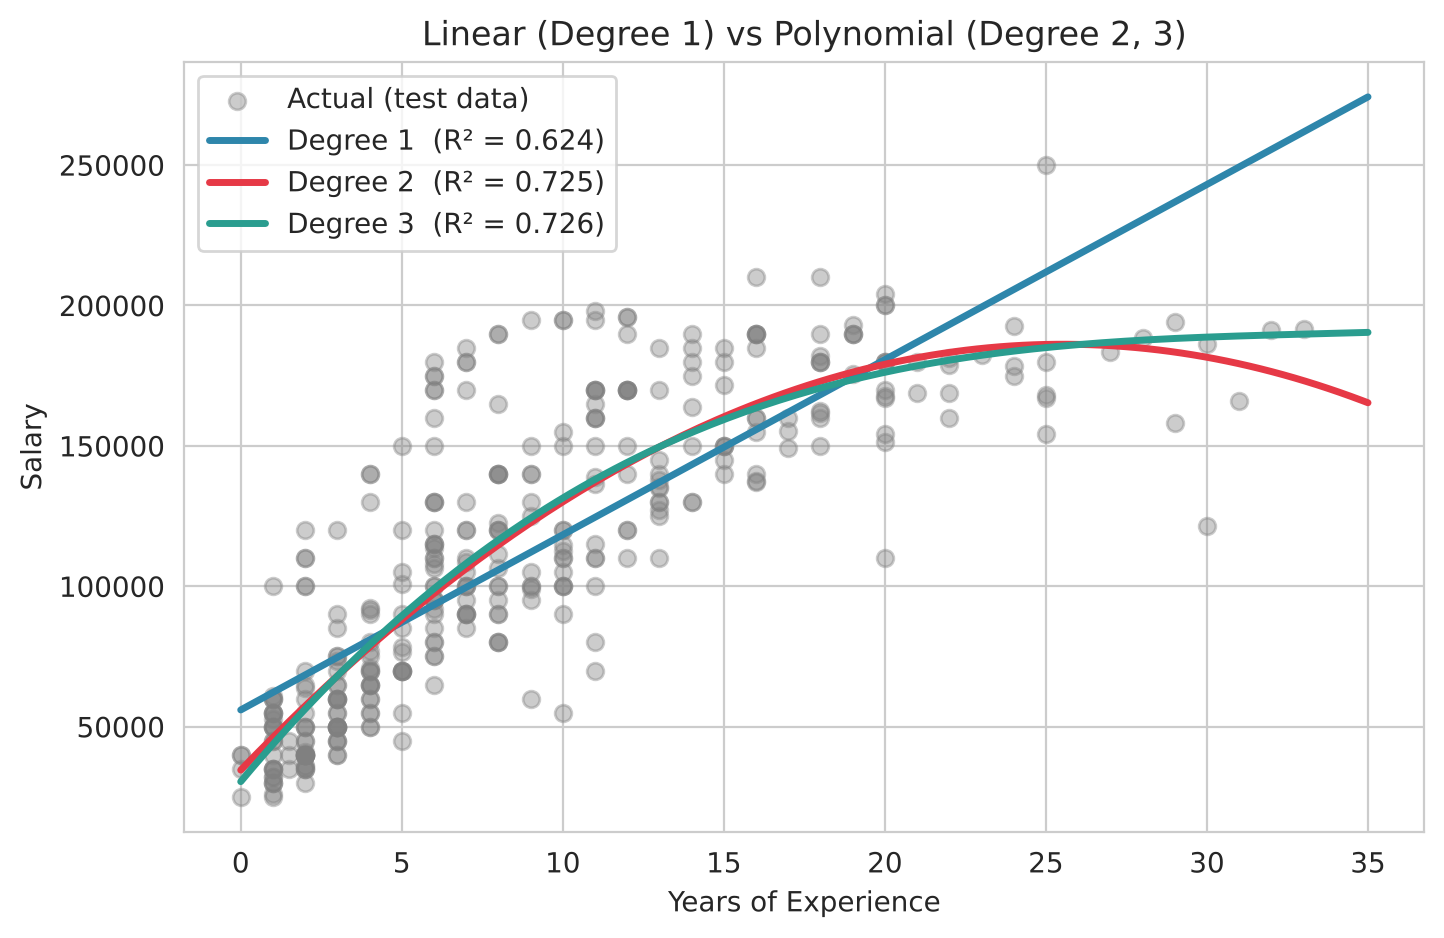

In [19]:
X_exp = df[["Years of Experience"]]
y = df["Salary"]

X_train_e, X_test_e, y_train_e, y_test_e = train_test_split(
    X_exp, y, test_size=0.2, random_state=42
)

# Ek smooth line banane ke liay 0 se 35 saal tak ki values
x_line = pd.DataFrame({"Years of Experience": np.linspace(0, 35, 200)})

plt.scatter(X_test_e, y_test_e, alpha=0.4, color="gray", label="Actual (test data)")

colors = {1: "#2E86AB", 2: "#E63946", 3: "#2A9D8F"}
for degree in [1, 2, 3]:
    model = Pipeline([
        ("poly", PolynomialFeatures(degree=degree, include_bias=False)),
        ("linear", LinearRegression())
    ])
    model.fit(X_train_e, y_train_e)
    score = r2_score(y_test_e, model.predict(X_test_e))
    plt.plot(x_line, model.predict(x_line), color=colors[degree], linewidth=2.5,
             label=f"Degree {degree}  (R² = {score:.3f})")

plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.title("Linear (Degree 1) vs Polynomial (Degree 2, 3)")
plt.legend()
plt.show()

**Result:** Blue seedhi line (Linear) data ko theek follow nahi kar paati. Laal aur hara **curve** data ke shape ke sath mur jata hai, aur R² score bhi behtar hai. Yahi Polynomial Regression ki taaqat hai! 💪

---
## Underfitting aur Overfitting 🎯

Degree chunna sab se important faisla hai:

| | Kya hota hai | Misaal |
|---|---|---|
| **Underfitting** (degree bohat kam) | Model bohat simple hai, pattern hi nahi pakar paata | Student ne kitaab hi nahi parhi. Practice mein bhi fail, exam mein bhi fail |
| **Good Fit** ✅ | Model ne asal pattern seekh liya | Student ne concept samjha. Dono mein ache marks |
| **Overfitting** (degree bohat zyada) | Model ne data **ratta** maar liya, noise bhi yaad kar liya | Student ne sirf past paper ratta liya. Practice mein 100%, naye exam mein fail |

**Overfitting ki pehchaan:** Training score bohat acha, lekin Test score bohat bura. Ye hum Part B mein apni aankhon se dekhein ge.

---
# 🅱️ Part B: Saare features ke sath Polynomial Regression

## Step 5: X aur y alag karna, aur Train/Test split

In [20]:
X = df.drop("Salary", axis=1)
y = df["Salary"]

print("Features:", list(X.columns))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Features: ['Age', 'Years of Experience', 'Education', 'Gender_Male', 'Gender_Other', 'Is_Senior', 'Is_Manager', 'Is_Junior']
Training rows: 1429
Testing rows: 358


## Step 6: Feature Scaling kyun zaroori hai? ⚖️

Hamare features ki ranges bohat alag hain:
- `Age`: 20 se 60
- `Education`: 0 se 3
- `Is_Senior`: 0 ya 1

Polynomial mein jab hum square karte hain to farq aur bhi bara ho jata hai: Age² = 3600 tak, jabke Education² sirf 9! Model bari values ko zyada ahmiyat dene lagta hai aur calculation bhi garbar ho sakti hai.

**StandardScaler** har column ko aisa bana deta hai ke uska average **0** aur phailao (standard deviation) **1** ho jaye. Ab sab features barabar ki ground pe hain.

$$ x_{scaled} = \frac{x - mean}{standard\ deviation} $$

## Step 7: Pipeline kya hai? 🔗

Hamare model ke 3 steps hain: **Polynomial features banao ➜ Scale karo ➜ Linear Regression**. Inko har baar alag alag chalana mushkil aur ghalti ka khatra hai. **Pipeline** in sab ko jor kar **ek hi model** bana deti hai. Bas `.fit()` aur `.predict()` karo, sab steps khud order mein chal jayein ge.

Factory ki assembly line socho: maal ek taraf se daalo, sab machines khud apna kaam kar ke dosri taraf tayyar product nikal deti hain. 🏭

In [21]:
def make_poly_model(degree):
    return Pipeline([
        ("poly",   PolynomialFeatures(degree=degree, include_bias=False)),
        ("scaler", StandardScaler()),
        ("linear", LinearRegression())
    ])

print("Model banane wala function tayyar ✅")

Model banane wala function tayyar ✅


## Step 8: Sahi Degree kaise chunein? (Cross Validation) 🔄

Degree chunne ke liay hum **test data use nahi karein ge**. Test data asal exam hai, usay aakhir tak chhupa ke rakhna hai.

Iski jagah **Cross Validation** use karte hain:
1. Training data ko **5 hisson** mein baant do
2. 4 hisson pe train karo, 5th pe check karo
3. Ye 5 baar karo, har baar alag hissa check ke liay
4. 5 scores ka **average** lo

Is se pata chalta hai model **naye data** pe kaisa perform kare ga, bina test data ko chhuay.

In [22]:
degrees = [1, 2, 3, 4, 5, 6]
train_scores, cv_scores = [], []

for d in degrees:
    model = make_poly_model(d)
    cv = cross_val_score(model, X_train, y_train, cv=5, scoring="r2").mean()
    model.fit(X_train, y_train)
    train = r2_score(y_train, model.predict(X_train))
    train_scores.append(train)
    cv_scores.append(cv)
    print(f"Degree {d}:  Training R² = {train:.3f}   |   Cross Validation R² = {cv:.3f}")

Degree 1:  Training R² = 0.764   |   Cross Validation R² = 0.761
Degree 2:  Training R² = 0.821   |   Cross Validation R² = 0.813
Degree 3:  Training R² = 0.837   |   Cross Validation R² = 0.795


Degree 4:  Training R² = 0.853   |   Cross Validation R² = 0.593


Degree 5:  Training R² = 0.869   |   Cross Validation R² = -8.452


Degree 6:  Training R² = 0.879   |   Cross Validation R² = -55.809


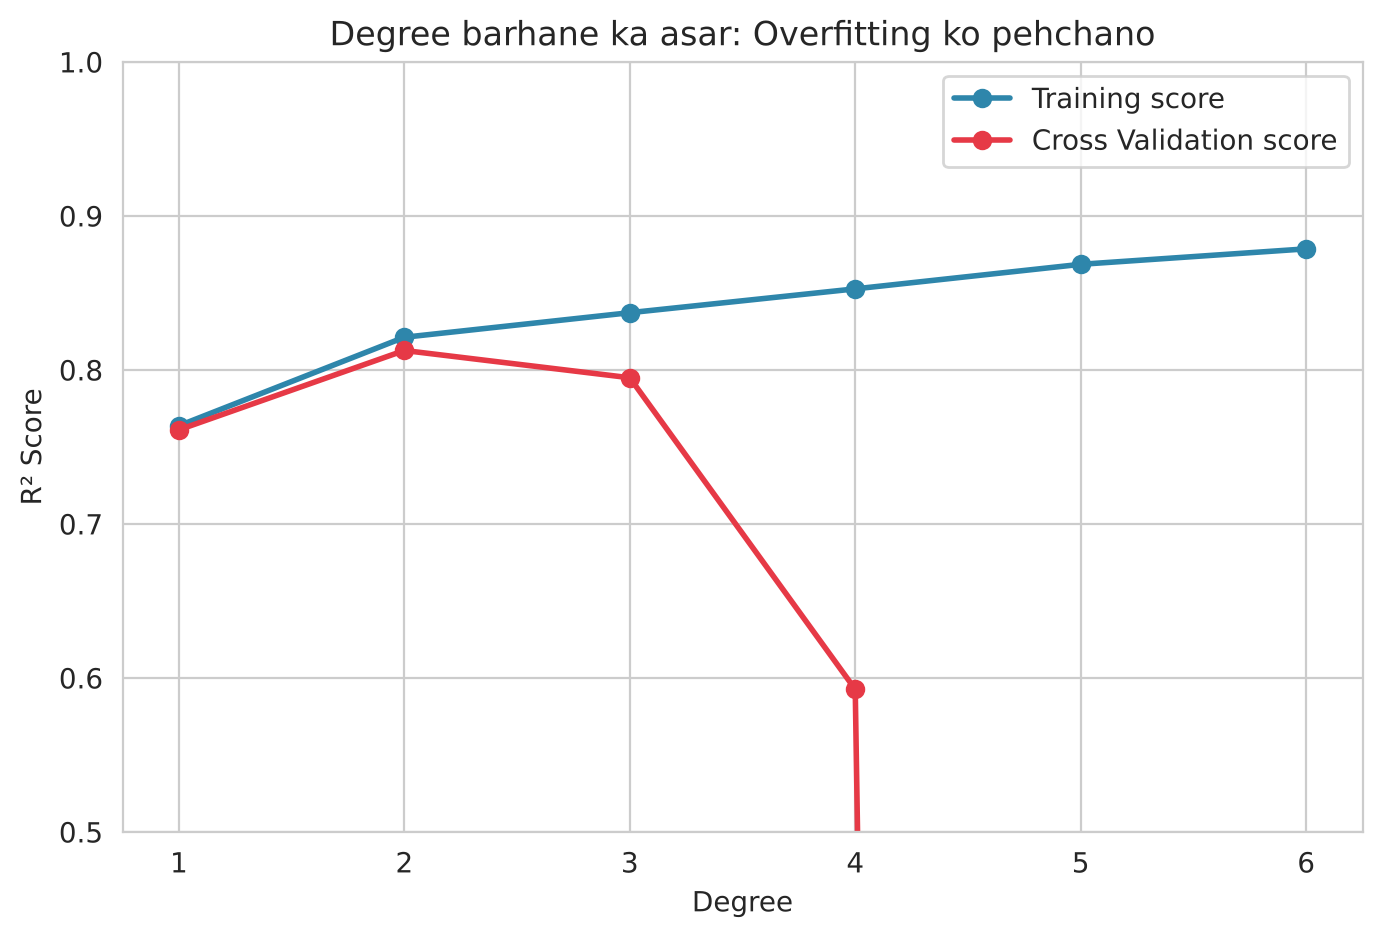

In [23]:
plt.plot(degrees, train_scores, "o-", color="#2E86AB", linewidth=2, label="Training score")
plt.plot(degrees, cv_scores, "o-", color="#E63946", linewidth=2, label="Cross Validation score")
plt.ylim(0.5, 1)
plt.xlabel("Degree")
plt.ylabel("R² Score")
plt.title("Degree barhane ka asar: Overfitting ko pehchano")
plt.legend()
plt.show()

**Ye graph bohat important hai! 👀**
- **Training score (blue)** degree ke sath barhta hi jata hai. Model training data ratta maar raha hai.
- **Cross Validation score (laal)** pehle barhta hai, phir **girne lagta hai** (degree 5 aur 6 pe to graph se bahar gir jata hai). Yahi **Overfitting** hai!

Jahan laal line sab se upar hai, wohi **best degree** hai. Code khud chun leta hai:

In [24]:
best_degree = degrees[int(np.argmax(cv_scores))]
print("Best degree:", best_degree)

Best degree: 2


## Step 9: Final model train karna aur Test pe check karna 🏁

Ab best degree ke sath final model banate hain, aur muqablay ke liay ek simple Linear Regression (degree 1) bhi.

In [25]:
linear_model = make_poly_model(1)
linear_model.fit(X_train, y_train)
y_pred_lin = linear_model.predict(X_test)

poly_model = make_poly_model(best_degree)
poly_model.fit(X_train, y_train)
y_pred_poly = poly_model.predict(X_test)

def evaluate(name, y_true, y_pred):
    return {
        "Model": name,
        "MAE": round(mean_absolute_error(y_true, y_pred)),
        "RMSE": round(np.sqrt(mean_squared_error(y_true, y_pred))),
        "R² Score": round(r2_score(y_true, y_pred), 3)
    }

results = pd.DataFrame([
    evaluate("Linear Regression", y_test, y_pred_lin),
    evaluate(f"Polynomial (degree {best_degree})", y_test, y_pred_poly)
])
results

,Model,MAE,RMSE,R² Score
0,Linear Regression,20987,27788,0.718
1,Polynomial (degree 2),18057,23520,0.798


Polynomial model ka error kam aur R² zyada hai. Matlab wo salary ko Linear se **behtar** samajh raha hai. 🎉

Yaad rakho: MAE matlab average kitne rupay ki ghalti, aur R² matlab model salary ke kitne hissay ko samajh paa raha hai (1 ke qareeb = behtareen).

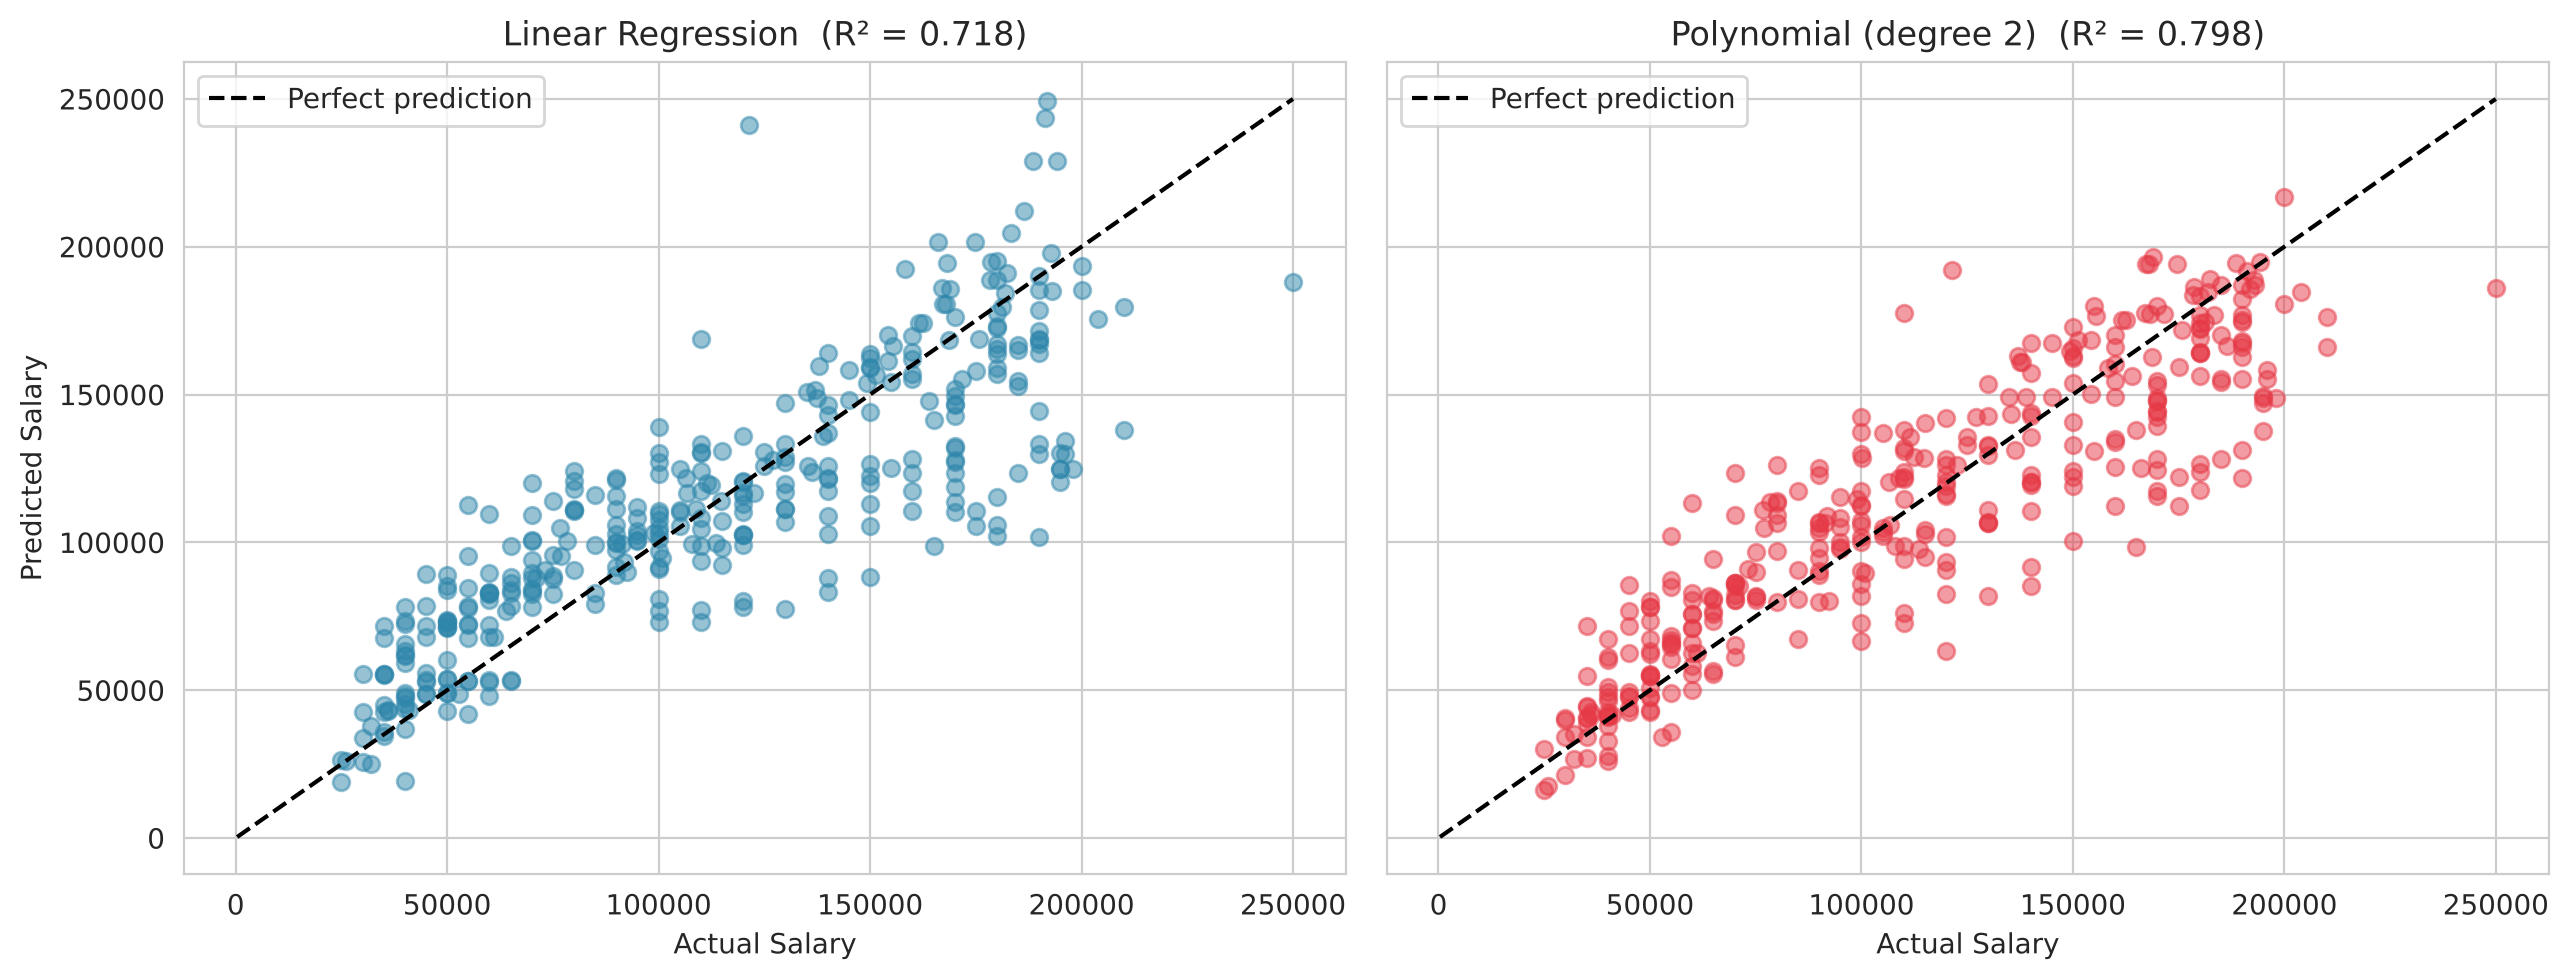

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)

for ax, pred, name, color in [
    (axes[0], y_pred_lin, "Linear Regression", "#2E86AB"),
    (axes[1], y_pred_poly, f"Polynomial (degree {best_degree})", "#E63946")
]:
    ax.scatter(y_test, pred, alpha=0.5, color=color)
    ax.plot([y.min(), y.max()], [y.min(), y.max()], "k--", linewidth=1.5, label="Perfect prediction")
    ax.set_title(f"{name}  (R² = {r2_score(y_test, pred):.3f})")
    ax.set_xlabel("Actual Salary")
    ax.legend()

axes[0].set_ylabel("Predicted Salary")
plt.tight_layout()
plt.show()

Dotted line pe jitne zyada dots, utna acha model. Polynomial wale dots line ke zyada qareeb hain, isi liay uska R² behtar hai.

---
# 🅲 Part C: Epoch, Batch, Learning Rate aur Loss ⏱️

Ye words aap ML aur Deep Learning mein baar baar sunein ge. Chalo inko asaan zubaan mein samjhte hain.

### Model seekhta kaise hai?
Do tareeqe hote hain:

**1) Seedha formula (Direct Solution):** `LinearRegression` math ka ek formula laga kar **ek hi baar** mein best line nikal leta hai. Isme **koi epoch nahi** hota. Isi liay humne ab tak epoch ka naam nahi suna. 😄

**2) Thora thora seekhna (Gradient Descent):** Model pehle **random guess** karta hai, ghalti check karta hai, thora sa sudharta hai, phir dobara... Bilkul jaise aap andheray mein pahar se neeche utar rahe ho: har qadam pe dekhte ho kidhar dhalaan hai aur us taraf ek chhota qadam le lete ho. ⛰️ Deep Learning ke saare models aise hi seekhte hain.

### Important words

| Word | Matlab | Misaal |
|---|---|---|
| **Epoch** | Model ne **poora** training data **ek baar** dekh liya | Poori kitaab ek baar parh li 📖 |
| **Batch** | Data ka **chhota hissa** jo ek waqt mein model ko diya jata hai | Kitaab ka ek chapter |
| **Iteration** | Ek batch pe seekhna (ek qadam) | Ek chapter parhna |
| **Learning Rate** | Har qadam kitna **bara** ho | Bohat bara qadam = gir sakte ho. Bohat chhota = bohat der lagay gi |
| **Loss** | Model ki **ghalti** kitni hai. Isay kam karna hi maqsad hai | Exam mein kitne ghalat jawab |

**Misaal:** Agar 1000 rows hain aur batch size 100 hai, to **1 epoch = 10 iterations**. Agar 50 epochs chalayein to model poora data 50 baar dekhe ga.

### Demo: Epochs ke sath seekhna dekhte hain 👀
`SGDRegressor` (Stochastic Gradient Descent) wohi Linear Regression hai, lekin ye **Gradient Descent** se thora thora seekhta hai. Hum isko apne polynomial features pe **har epoch alag** chalayein ge aur dekhein ge ke loss kaise kam hota hai.

In [27]:
# Wohi polynomial + scaling steps jo final model mein the
prep = Pipeline([
    ("poly",   PolynomialFeatures(degree=best_degree, include_bias=False)),
    ("scaler", StandardScaler())
])
X_train_ready = prep.fit_transform(X_train)
X_test_ready  = prep.transform(X_test)

# Salary ko hazaron mein kar dete hain taa ke numbers chhote rahein (90000 -> 90)
y_train_k = y_train / 1000
y_test_k  = y_test / 1000

sgd = SGDRegressor(learning_rate="constant", eta0=0.0001, random_state=42)

epochs = 100
train_loss, test_loss = [], []

for epoch in range(1, epochs + 1):
    sgd.partial_fit(X_train_ready, y_train_k)   # 1 epoch = poora data ek baar

    train_loss.append(mean_squared_error(y_train_k, sgd.predict(X_train_ready)))
    test_loss.append(mean_squared_error(y_test_k, sgd.predict(X_test_ready)))

    if epoch in [1, 5, 10, 25, 50, 100]:
        print(f"Epoch {epoch:2d}  ->  Loss (MSE) = {train_loss[-1]:,.1f}")

Epoch  1  ->  Loss (MSE) = 10,535.9
Epoch  5  ->  Loss (MSE) = 3,783.8
Epoch 10  ->  Loss (MSE) = 1,428.4
Epoch 25  ->  Loss (MSE) = 672.4
Epoch 50  ->  Loss (MSE) = 628.0


Epoch 100  ->  Loss (MSE) = 588.9


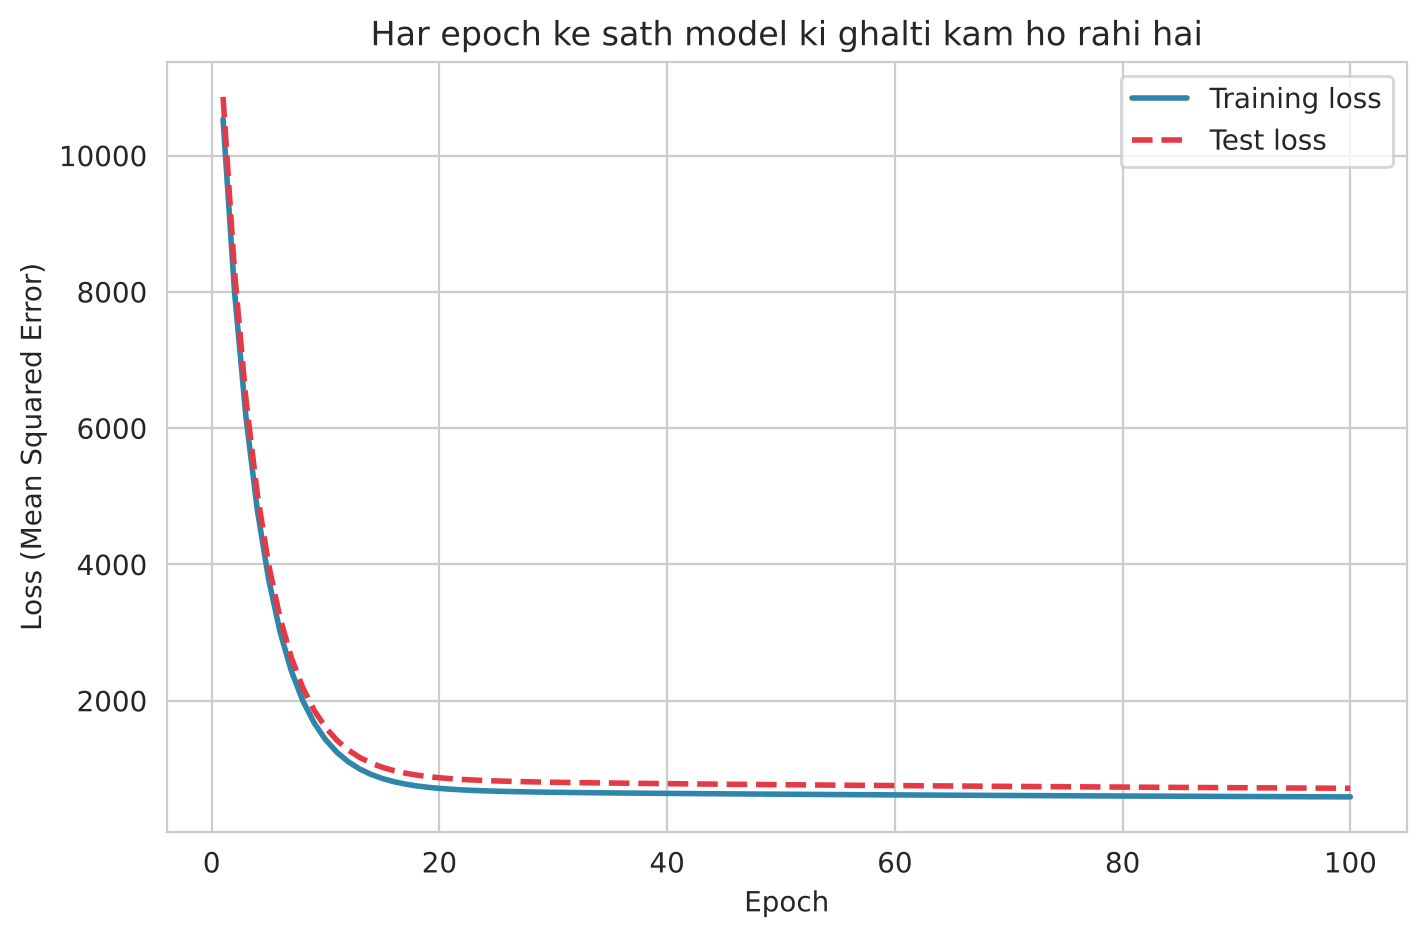

SGD model ka R² score (100 epochs ke baad): 0.739


In [28]:
plt.plot(range(1, epochs + 1), train_loss, color="#2E86AB", linewidth=2, label="Training loss")
plt.plot(range(1, epochs + 1), test_loss, color="#E63946", linewidth=2, linestyle="--", label="Test loss")
plt.xlabel("Epoch")
plt.ylabel("Loss (Mean Squared Error)")
plt.title("Har epoch ke sath model ki ghalti kam ho rahi hai")
plt.legend()
plt.show()

print(f"SGD model ka R² score ({epochs} epochs ke baad): {r2_score(y_test_k, sgd.predict(X_test_ready)):.3f}")

**Graph samjho:**
- Pehle epochs mein loss **tezi se girta** hai, kyunke model ke random guesses bohat ghalat the aur jaldi sudhar gaye
- Phir loss girna **slow** ho jata hai aur line **flat** ho jati hai. Iska matlab model ne jitna seekhna tha seekh liya. Isko **Convergence** kehte hain ✅
- SGD ka score `LinearRegression` ke qareeb pohanch jata hai, jisne yahi kaam formula se ek hi baar mein kar diya tha. Zyada epochs do to aur qareeb aaye ga

> 💡 Deep Learning mein bhi aap aise hi loss ka graph dekhein ge. Agar **training loss girta rahe lekin test loss upar jane lage**, to samajh jao **overfitting** shuru ho gayi hai, aur training rok deni chahiye.

**Khud try karo:** Learning rate `eta0=0.0001` ko `0.001` kar ke chalao. Loss kuch epochs baad **kam hone ki bajaye phat jaye ga** (bohat bara ho jaye ga), kyunke qadam itne bare hain ke model sahi jagah se aage nikal jata hai. Phir `0.00001` kar ke dekho, seekhna bohat slow ho jaye ga. Sahi learning rate dhoondna bhi ek fun hai! 🎯

---
# 🅳 Part D: Model ko Pickle file mein save karna 💾

### Pickle kya hai?
Abhi hamara model sirf is notebook ki **memory** mein hai. Notebook band hui, model gaya! Har baar dobara train karna parega.

**Pickle** Python ka tareeqa hai kisi bhi cheez (model, list, dictionary) ko **file mein save** karne ka. Baad mein wohi file load kar ke model foran use kar sakte hain. Website, app ya kisi aur project mein bhi. 🚀

Socho jaise khana bana ke **freezer** mein rakh diya. Jab zaroorat ho nikala, garam kiya, aur kha liya. Dobara pakane ki zaroorat nahi. 🍱

### Kya save karna hai?
Sirf model nahi! Naye data ko bhi **bilkul usi tarah** tayyar karna hoga jaise training data kiya tha. Isliay hum ek package bana kar save karein ge jisme ho:
- **Model** (pipeline jisme polynomial, scaler aur regression sab hai)
- **Features ki list** (sahi order mein)
- **Education ka mapping**

In [29]:
model_package = {
    "model": poly_model,
    "features": list(X.columns),
    "education_map": education_map,
    "degree": best_degree
}

with open("salary_polynomial_model.pkl", "wb") as file:   # "wb" = write binary
    pickle.dump(model_package, file)

print("Model save ho gaya: salary_polynomial_model.pkl ✅")

Model save ho gaya: salary_polynomial_model.pkl ✅


### Ab model ko wapis load karna 📂
Socho ye bilkul naya notebook ya app hai. Hum sirf `.pkl` file load karte hain, koi training nahi.

In [30]:
with open("salary_polynomial_model.pkl", "rb") as file:    # "rb" = read binary
    loaded = pickle.load(file)

loaded_model = loaded["model"]

print("Model load ho gaya ✅")
print("Degree:", loaded["degree"])
print("Features:", loaded["features"])

Model load ho gaya ✅
Degree: 2
Features: ['Age', 'Years of Experience', 'Education', 'Gender_Male', 'Gender_Other', 'Is_Senior', 'Is_Manager', 'Is_Junior']


### Naye insaan ki salary predict karo! 💰

Ye function raw information leta hai (jaise form mein bhari jati hai), usay **wohi preprocessing** deta hai jo humne Step 4 mein ki thi, aur salary bata deta hai.

In [31]:
def predict_salary(age, gender, education, job_title, experience, package=loaded):
    title = job_title.lower()
    row = {
        "Age": age,
        "Years of Experience": experience,
        "Education": package["education_map"][education],
        "Gender_Male": 1 if gender == "Male" else 0,
        "Gender_Other": 1 if gender == "Other" else 0,
        "Is_Senior":  int(any(w in title for w in ["senior", "sr", "lead", "principal"])),
        "Is_Manager": int(any(w in title for w in ["manager", "director", "head", "vp", "chief", "ceo", "cto"])),
        "Is_Junior":  int(any(w in title for w in ["junior", "jr", "assistant", "intern", "coordinator"])),
    }
    new_person = pd.DataFrame([row])[package["features"]]   # columns ka order training wala
    return package["model"].predict(new_person)[0]


salary = predict_salary(age=28, gender="Female", education="Master's",
                        job_title="Data Scientist", experience=4)
print(f"Andazan salary: {salary:,.0f}")

salary = predict_salary(age=40, gender="Male", education="PhD",
                        job_title="Senior Data Scientist", experience=15)
print(f"Andazan salary: {salary:,.0f}")

Andazan salary: 96,295
Andazan salary: 158,538


> ⚠️ **Do zaroori baatein:**
> 1. Pickle file load karte waqt `scikit-learn` ka **wohi version** hona chahiye jis mein save ki thi, warna error aa sakta hai.
> 2. Kabhi bhi **anjaan insaan ki di hui** `.pkl` file load na karo. Pickle file ke andar code chhupa ho sakta hai jo aapke computer pe chal jaye. Sirf apni ya bharosay wali files load karo. 🔒

> 💡 **Colab mein ho?** File download karne ke liay ye chalao:
> ```python
> from google.colab import files
> files.download("salary_polynomial_model.pkl")
> ```

---
## 📚 Summary: Aaj humne kya seekha

1. **Polynomial Regression:** x², x³ jaise columns add kar ke Linear Regression se **curve** banana
2. **Preprocessing:** missing values drop kiye, **duplicates** hataye, ek jaisi categories ke naam theek kiye, Education ki **ordinal** aur Gender ki **one-hot** encoding ki, aur Job Title se level nikala (**feature engineering**)
3. **Underfitting vs Overfitting:** degree bohat kam = kuch nahi seekha, bohat zyada = ratta maar liya
4. **Feature Scaling** (StandardScaler) aur **Pipeline** (sab steps ek model mein)
5. **Cross Validation** se best degree chuni, test data ko chhuay baghair
6. **Epoch, Batch, Learning Rate, Loss** aur Gradient Descent se thora thora seekhna
7. Model ko **Pickle** mein save aur load kar ke naye logon ki salary predict ki

### Workflow jo har project mein kaam aaye ga 🔁
Data load ➜ Explore ➜ **Clean (missing, duplicates, categories)** ➜ Encode ➜ Split ➜ Pipeline (Poly + Scale + Model) ➜ Cross Validation se tuning ➜ Final test ➜ **Pickle save**

---
## ✍️ Homework / Practice

1. Part A mein degree `[1, 2, 3]` ki jagah `[1, 2, 10]` kar ke dekho. Degree 10 ka curve kaisa lagta hai?
2. Step 4.2 (duplicates hatana) ko comment kar ke poora notebook dobara chalao. R² score pe kya asar para? Kya wo score sach mein bharosay ke qabil hai?
3. Part C mein `epochs = 100` ko `5` kar do. Model ka R² score kitna aaya?
4. `predict_salary()` mein apni marzi ki 3 profiles daal kar salary predict karo. Experience 0 se 30 tak badal kar dekho salary kaise barhti hai
5. **Challenge:** Job Title se ek aur level feature bana sakte ho? (jaise "Engineer" ya "Analyst" wale log)

**Shabash! Ab aap curve wale data ko bhi handle kar sakte ho aur apna model save bhi kar sakte ho. 🎓**